# 01 — Exploración de la OBT

Objetivo: comprender calidad y estructura antes de entrenar. Adaptado al patrón de semana 8 sesión 2: código → resultado → conclusión. No imputamos, eliminamos filas ni entrenamos en este notebook.

Primera fase: auditoría descriptiva general. Las correlaciones y decisiones de modelado se añadirán sobre entrenamiento después de aprobar los grupos y reservar test.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Abre el notebook desde pset_3")
sys.path.insert(0, str(ROOT))
import pandas as pd
from src.datos import cargar_snapshot

## 1. Elegir un snapshot
Primero exportaremos la OBT y registraremos su fecha y hash. Mantener una ruta explícita para reproducir este análisis.

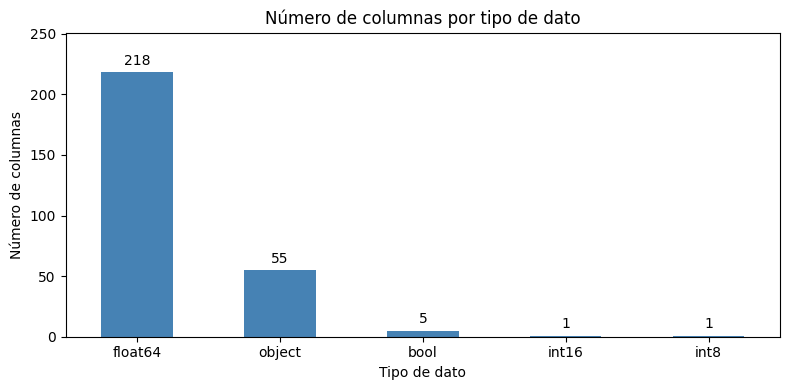

,columna,faltantes
0,GEOMETRY_ISSUE,11930
1,USES_REFERENCE_FOR_MUTATION,9311
2,SUBGROUP_RAW,9209
3,MUTATIONS_RAW,5230
4,TEMPERATURE_RAW,4535
5,TEMPERATURE_K,4535
6,AFFINITY_METHOD,4019
7,AFFINITY_METHOD_RAW,3765
8,AFFINITY_PMID,1304
9,AFFINITY_RELEASE_DATE_RAW,549


In [2]:
import json
import matplotlib.pyplot as plt

config = ROOT / "configs/dataset.local.json"
SNAPSHOT = ROOT / json.loads(config.read_text())["snapshot"] if config.exists() else None
if SNAPSHOT is None:
    raise FileNotFoundError("Selecciona el snapshot en configs/dataset.local.json")

datos, manifiesto = cargar_snapshot(SNAPSHOT)
datos_originales = datos.copy()  # OBT completa para recuperar columnas y repetir la selección.

# Los tipos son categorías: usamos barras para contar las columnas de cada tipo.
conteo_tipos = datos.dtypes.astype(str).value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
conteo_tipos.plot.bar(ax=ax, color="steelblue", rot=0)
ax.set(title="Número de columnas por tipo de dato", xlabel="Tipo de dato", ylabel="Número de columnas")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

# Solo columnas con al menos un valor faltante, ordenadas de mayor a menor.
faltantes = datos.isna().sum()
tabla_faltantes = (
    faltantes[faltantes > 0]
    .sort_values(ascending=False)
    .rename_axis("columna")
    .reset_index(name="faltantes")
)
with pd.option_context("display.max_rows", None):
    display(tabla_faltantes)


## 1.1. Selección inicial de columnas (sin eliminar observaciones)

Aplicamos los cuatro criterios a una copia en memoria. `datos_originales` conserva las 280 columnas; `datos` conserva todas las filas y solo las columnas seleccionadas. El snapshot y Snowflake no se modifican.

1. **Fuga de la etiqueta:** quitar Kd numérico y textual, conservar **PKD** como respuesta.
2. **Identificación y procedencia:** quitar metadatos innecesarios para esta exploración. Excepción: conservar identificadores, cadenas y referencias necesarios para revisar observaciones y formar grupos biológicos.
3. **Disponibilidad al predecir:** por ahora suponemos una entrada estructural, sin garantizar el método ni la temperatura de la medición de afinidad. Excluimos esos campos como predictores; si después definimos que recibiremos temperatura, revisaremos esa decisión. No significa que la temperatura sea intrínsecamente una fuga de datos.
4. **Vacías o constantes:** comprobar las candidatas restantes; no borrar columnas de control aunque sean constantes. Una columna con un valor conocido más NULL no es completamente constante: conserva un patrón de ausencia.

`columnas_control` se conservan **solo para auditoría, filtros y agrupación**, no como entradas de ML. `features_candidatas` contiene únicamente las posibles entradas y excluye PKD. La selección estadística definitiva se ajustará con entrenamiento, dentro del pipeline; esta celda no crea el split ni selecciona por correlación o rendimiento.


In [3]:
# Si ya cargaste el notebook antes de añadir esta celda, conserva el original.
if "datos_originales" not in globals():
    datos_originales = datos.copy()
datos = datos_originales.copy()

# El diccionario distingue etiqueta, candidatos, controles y procedencia.
diccionario = json.loads((ROOT / "docs/obt_data_dictionary.json").read_text())
roles = {col["name"]: col["ml_role"] for col in diccionario["columns"]}
sin_definicion = set(datos.columns) - set(roles)
if sin_definicion:
    raise ValueError(f"Revisar columnas sin definición: {sorted(sin_definicion)}")

# Excepciones: conservar datos necesarios para filtrar o agrupar observaciones.
conservar_para_revision = {
    "OBSERVATION_ID", "PDB_ID", "COMPLEX_ID", "GEOMETRY_ID", "EXPERIMENT_KEY",
    "LIGAND_NAME", "RECEPTOR_NAME", "LIGAND_CHAINS_RAW", "RECEPTOR_CHAINS_RAW",
    "LIGAND_CHAINS_JSON", "RECEPTOR_CHAINS_JSON", "MUTATIONS_RAW", "SUBGROUP_RAW",
    "SOURCE_DATASET", "STRUCTURE_SHA256", "AFFINITY_REFERENCE_RAW", "AFFINITY_PMID",
    "STRUCTURE_METHOD_RAW", "TEMPERATURE_RAW", "HAS_CA_CONTACTS_10",
}
columnas_control = [
    col for col in datos
    if roles[col] == "quality_control" or col in conservar_para_revision
]
protegidas = set(columnas_control) | {"PKD"}

# Criterios 1–3: significado de la columna y disponibilidad en inferencia.
# No buscar por la palabra "KD": KD_HYDROPATHY es hidropatía, no afinidad.
motivos = {}
for col in datos:
    if col in protegidas:
        continue
    if roles[col] == "target_leakage":
        motivos[col] = "1. Contiene la afinidad experimental"
    elif roles[col] in {"identifier", "provenance"}:
        motivos[col] = "2. Identificación o trazabilidad no necesaria en datos"
    elif roles[col] in {"context", "conditional_predictor"}:
        motivos[col] = "3. No incluida en el contrato de entrada estructural actual"

# Criterio 4: solo las candidatas no protegidas y aún no descartadas.
# Conservamos columnas parcialmente nulas: faltantes no equivale a constante.
for col in datos:
    if col in protegidas or col in motivos:
        continue
    if datos[col].isna().all():
        motivos[col] = "4. Columna completamente vacía"
    elif datos[col].nunique(dropna=False) == 1:
        motivos[col] = "4. Columna constante, incluido su estado de ausencia"

columnas_eliminadas = pd.DataFrame(
    [(col, motivo) for col, motivo in motivos.items()],
    columns=["columna", "criterio"],
)
datos = datos.drop(columns=list(motivos)).copy()
features_candidatas = [
    col for col in datos
    if roles[col] == "predictor_candidate" and col not in protegidas
]

# Garantía: se mantienen filas, orden, etiquetas y controles, incluidos fallos.
assert datos.index.equals(datos_originales.index)
assert datos["OBSERVATION_ID"].equals(datos_originales["OBSERVATION_ID"])
assert datos["PKD"].equals(datos_originales["PKD"])
assert datos[columnas_control].equals(datos_originales[columnas_control])
assert not {"KD_M", "KD_M_RAW", "PKD"}.intersection(features_candidatas)

print(f"Filas: {len(datos):,} (ninguna eliminada)")
print(f"Columnas: {datos_originales.shape[1]} → {datos.shape[1]}")
print(f"Candidatas: {len(features_candidatas)}; controles: {len(columnas_control)}; etiqueta: PKD")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(columnas_eliminadas)


Filas: 12,062 (ninguna eliminada)
Columnas: 280 → 253
Candidatas: 173; controles: 79; etiqueta: PKD


,columna,criterio
0,SOURCE_KEY,2. Identificación o trazabilidad no necesaria en datos
1,LIGAND_PARTICIPANT_KEY,2. Identificación o trazabilidad no necesaria en datos
2,RECEPTOR_PARTICIPANT_KEY,2. Identificación o trazabilidad no necesaria en datos
3,SOURCE_ROW,2. Identificación o trazabilidad no necesaria en datos
4,SOURCE_INDEX_RAW,2. Identificación o trazabilidad no necesaria en datos
5,KD_M,1. Contiene la afinidad experimental
6,KD_M_RAW,1. Contiene la afinidad experimental
7,STRUCTURE_REFERENCE_RAW,2. Identificación o trazabilidad no necesaria en datos
8,STRUCTURE_RELEASE_DATE_RAW,2. Identificación o trazabilidad no necesaria en datos
9,STRUCTURE_VERSIONS,2. Identificación o trazabilidad no necesaria en datos


## 2. Grano y fingerprints de distancias mínimas completas

**Pregunta:** ¿cuántas geometrías comparten las distancias mínimas de todos sus residuos, aunque cambien las letras de cadena o el orden L/R?

**Justificación:** varias observaciones reutilizan estructuras de referencia. Comparar filas completas de la OBT mezcla geometría con identificadores y afinidad. Construimos un descriptor exclusivamente geométrico por `GEOMETRY_ID` para explorar esa repetición antes del splitting.

**Datos:** mínimos Cα de TODOS los residuos utilizables de ambos participantes, sin filtrar por `SELECTED_Q1`. Se recuperan de Silver, no de los resúmenes de la OBT. Los residuos experimentalmente ausentes no se inventan. `minimos_completos.parquet` contiene una lista de distancias por participante y los hashes de sus archivos originales; el manifiesto lo vincula al snapshot.

**Algoritmo:** ordenar los mínimos de cada participante; ordenar también ambos vectores para permitir intercambiar L/R; conservar longitudes y multiplicidades; serializar y obtener un SHA-256. El hash es una etiqueta compacta del vector, no una nueva medición ni un embedding aprendido. No utiliza pKd, identidad de aminoácidos ni mutaciones.

- `FP_MINIMA_EXACT`: coincidencia exacta de los vectores ordenados.
- `FP_MINIMA_ROUND3`: coincidencia después de redondear a 3 decimales (0,001 Å). Es una exploración de sensibilidad, no un umbral validado ni una tolerancia de comparación. Valores cercanos a un borde de redondeo pueden separarse.

Coincidir significa compartir este descriptor: no demuestra por sí solo equivalencia estructural completa. No asignamos equivalencia biológica, no elegimos afinidades, no eliminamos observaciones y no hacemos todavía el split. Las columnas `FP_*` son auxiliares; no se agregan a `features_candidatas`.


In [4]:
from src.fingerprints import crear_fingerprints, unir_fingerprints
import hashlib

CARPETA_FP = ROOT / "data/fingerprints" / SNAPSHOT.name
archivo_minimos = CARPETA_FP / "minimos_completos.parquet"
if not archivo_minimos.exists():
    raise FileNotFoundError("Prepara los mínimos siguiendo docs/fingerprints.md")
manifest_fp = json.loads((CARPETA_FP / "manifest.json").read_text())
assert manifest_fp["snapshot_sha256"] == manifiesto["sha256"], "El origen no corresponde a esta OBT"
assert hashlib.sha256(archivo_minimos.read_bytes()).hexdigest() == manifest_fp["sha256"]
minimos = pd.read_parquet(archivo_minimos)
ids_esperados = set(datos.loc[datos.GEOMETRY_STATUS.eq("computed"), "GEOMETRY_ID"])
assert set(minimos.GEOMETRY_ID) == ids_esperados
fingerprints = crear_fingerprints(minimos)

# Unión many-to-one: todas las observaciones de una geometría reciben su fingerprint.
filas_antes = len(datos)
datos = unir_fingerprints(datos, fingerprints)
assert len(datos) == filas_antes
assert datos.PKD.equals(datos_originales.PKD)
assert not set(c for c in datos if c.startswith("FP_")).intersection(features_candidatas)
fingerprints.to_parquet(CARPETA_FP / "fingerprints.parquet", index=False)

resumen_fp = []
for col in ["FP_MINIMA_EXACT", "FP_MINIMA_ROUND3"]:
    tamanos = fingerprints.groupby(col).size()
    resumen_fp.append({"criterio": col, "geometrias": len(fingerprints),
                       "fingerprints_distintos": len(tamanos),
                       "grupos_con_varias_geometrias": int((tamanos > 1).sum()),
                       "geometrias_en_esos_grupos": int(tamanos[tamanos > 1].sum())})
display(pd.DataFrame(resumen_fp))
print(f"Observaciones: {len(datos):,}; con fingerprint: {datos.FP_MINIMA_EXACT.notna().sum():,}")
print(f"Residuos usados: {manifest_fp['residue_count']:,}; sin filtro Q1")


,criterio,geometrias,fingerprints_distintos,grupos_con_varias_geometrias,geometrias_en_esos_grupos
0,FP_MINIMA_EXACT,4716,4463,253,506
1,FP_MINIMA_ROUND3,4716,4463,253,506


Observaciones: 12,062; con fingerprint: 11,927
Residuos usados: 2,298,656; sin filtro Q1


In [5]:
# Distinguir reutilización de una geometría de coincidencias entre geometrías distintas.
grupo_fp = "FP_MINIMA_EXACT"
grupos_fingerprint = (
    datos.loc[datos[grupo_fp].notna()]
    .groupby(grupo_fp)
    .agg(observaciones=("OBSERVATION_ID", "size"),
         geometrias=("GEOMETRY_ID", "nunique"),
         pdb_distintos=("PDB_ID", "nunique"))
    .sort_values(["geometrias", "observaciones"], ascending=False)
    .reset_index()
)
grupos_fingerprint.to_csv(CARPETA_FP / "grupos_fingerprint.csv", index=False)
display(grupos_fingerprint.head(20))
print("Grupos con más de una geometría:", (grupos_fingerprint.geometrias > 1).sum())

# Solo diagnóstico: no deduplicar con drop_duplicates ni escoger una afinidad.


,FP_MINIMA_EXACT,observaciones,geometrias,pdb_distintos
0,bb471aa1e4a73000f4cc81383dca79e671984d2d093cc4...,287,2,1
1,6866f40afddee5b7e7c11844cd6fe4f43af908b8c04dd1...,251,2,1
2,c3d2e94a2bced0362507e1a8e9203a31460e7a13613a41...,217,2,1
3,c4f562e8d5eb0d71669034a6a22639b528749f866891c3...,89,2,1
4,c4d4b28c0f41a5ee0e182393d7b4386846640c6c120ea9...,49,2,1
5,74e5bb32a37be8a8e3753be8a09135e600b1c0d424f9b5...,48,2,1
6,b763ecfad2c25f275b22a308f77d3c0906e92224a7eab7...,38,2,1
7,af19096629d8a5a80aa115094ef80ce3e2a9ebdbfed380...,34,2,1
8,ec3791fccf5cd9f3b7a5f25c29b095d7c00c78d8438cb8...,34,2,1
9,10ed4a9e9ff027d1250aa1129c56ca2df130b7b406b1a3...,29,2,1


Grupos con más de una geometría: 253


**Interpretación:** un grupo con muchas observaciones pero una sola geometría indica reutilización de la misma estructura calculada. Un grupo con varias geometrías indica coincidencia entre descriptores de cálculos distintos. Revisaremos esos candidatos con coordenadas antes de descartar estructuras. La ausencia de coincidencia exacta tampoco descarta similitud estructural.

**Resultado del snapshot actual:** 2 298 656 residuos de 4 716 geometrías produjeron 4 463 fingerprints exactos. Hay 253 grupos de dos geometrías (506 geometrías en total) con el mismo descriptor; el redondeo a 0,001 Å no añadió coincidencias. Se conservan las 12 062 observaciones: 11 927 tienen fingerprint y 135 no tienen geometría calculada. Esto identifica candidatos a revisión, no 4 463 estructuras biológicas únicas confirmadas.


### 2.1. Afinidad disponible para una fila por fingerprint

Antes de seleccionar una observación representante, revisamos la correspondencia de la etiqueta. Priorizamos las observaciones con `MUTATION_STRUCTURE_STATUS == "not_annotated"`: esto significa **sin mutación anotada**, no una verificación experimental independiente de wild type.

- **Sin conflicto registrado:** una única afinidad entre las observaciones sin mutación anotada del grupo.
- **Afinidad pendiente:** varias afinidades entre esas observaciones; no elegir la primera ni promediarlas automáticamente.
- **Solo mutaciones anotadas:** el grupo no tiene observaciones sin mutación anotada; requiere revisión antes de asignar afinidad de referencia.

La tabla de auditoría conserva una fila por fingerprint. No elimina observaciones de `datos`, no deduplica las fuentes y no asigna etiquetas a los casos pendientes. Los umbrales de similitud del fingerprint no se eligen en función de estas afinidades.


In [6]:
# Revisión de etiquetas: independiente de cómo se calculó el fingerprint.
con_fp = datos.loc[datos.FP_MINIMA_EXACT.notna()]
sin_mutacion_anotada = con_fp.loc[con_fp.MUTATION_STRUCTURE_STATUS.eq("not_annotated")]
resumen_etiquetas = (
    sin_mutacion_anotada.groupby("FP_MINIMA_EXACT")
    .agg(observaciones_sin_mutacion_anotada=("OBSERVATION_ID", "size"),
         afinidades_sin_mutacion_anotada=("PKD", "nunique"))
    .reset_index()
)
auditoria_seleccion = grupos_fingerprint.merge(
    resumen_etiquetas, on="FP_MINIMA_EXACT", how="left", validate="one_to_one"
)
for col in ["observaciones_sin_mutacion_anotada", "afinidades_sin_mutacion_anotada"]:
    auditoria_seleccion[col] = auditoria_seleccion[col].fillna(0).astype(int)
auditoria_seleccion["estado_seleccion"] = "solo_mutaciones_anotadas"
auditoria_seleccion.loc[auditoria_seleccion.afinidades_sin_mutacion_anotada.eq(1), "estado_seleccion"] = "sin_conflicto_registrado"
auditoria_seleccion.loc[auditoria_seleccion.afinidades_sin_mutacion_anotada.gt(1), "estado_seleccion"] = "varias_afinidades_de_referencia"
assert len(auditoria_seleccion) == fingerprints.FP_MINIMA_EXACT.nunique()
auditoria_seleccion.to_csv(CARPETA_FP / "auditoria_seleccion.csv", index=False)
display(auditoria_seleccion.estado_seleccion.value_counts().rename_axis("estado").to_frame("fingerprints"))


,fingerprints
estado,
sin_conflicto_registrado,4345
varias_afinidades_de_referencia,102
solo_mutaciones_anotadas,16


### 2.2. Tabla filtrada: una observación por fingerprint sin conflicto registrado

**Decisión:** conservar únicamente los grupos con una afinidad única entre observaciones sin mutación anotada. Guardar los otros grupos aparte, sin asignarles una afinidad arbitraria.

La tabla `datos_filtrados` conserva las columnas de `datos` y una sola observación por `FP_MINIMA_EXACT`. Solo se seleccionan filas `not_annotated` y con geometría `computed`. Si hay varias candidatas con el mismo pKd, se conserva la primera al ordenar por `GEOMETRY_ID` y `OBSERVATION_ID`; esta regla es reproducible y no utiliza el valor de afinidad para favorecer una fila.

`datos` conserva todas las observaciones con sus fingerprints. `fingerprints_pendientes` tiene una fila por grupo pendiente y `observaciones_pendientes` conserva todas sus observaciones para poder revisar mutaciones y condiciones. La OBT y Snowflake no se modifican.

**Alcance:** sin mutación anotada no significa identidad experimental verificada; compartir un fingerprint de mínimos no demuestra equivalencia estructural. Esta selección usa la consistencia de la etiqueta para definir un conjunto exploratorio más restringido: se debe declarar en la evaluación y conservar los pendientes. Los fingerprints distintos aún pueden ser similares; esto no sustituye el splitting por grupos relacionados.


In [7]:
# Grupos aprobados y pendientes según la auditoría anterior.
ids_aprobados = set(auditoria_seleccion.loc[
    auditoria_seleccion.estado_seleccion.eq("sin_conflicto_registrado"), "FP_MINIMA_EXACT"
])
fingerprints_pendientes = auditoria_seleccion.loc[
    ~auditoria_seleccion.FP_MINIMA_EXACT.isin(ids_aprobados)
].copy()

candidatas = datos.loc[
    datos.FP_MINIMA_EXACT.isin(ids_aprobados)
    & datos.MUTATION_STRUCTURE_STATUS.eq("not_annotated")
    & datos.GEOMETRY_STATUS.eq("computed")
].copy()
# Un único valor de PKD, sin valores ausentes, entre las candidatas de cada grupo.
assert candidatas.PKD.notna().all()
assert candidatas.groupby("FP_MINIMA_EXACT").PKD.nunique().eq(1).all()
datos_filtrados = (
    candidatas.sort_values(["FP_MINIMA_EXACT", "GEOMETRY_ID", "OBSERVATION_ID"])
    .drop_duplicates("FP_MINIMA_EXACT", keep="first")
    .reset_index(drop=True)
)
observaciones_pendientes = datos.loc[
    datos.FP_MINIMA_EXACT.isin(fingerprints_pendientes.FP_MINIMA_EXACT)
].copy()
assert datos_filtrados.FP_MINIMA_EXACT.is_unique
assert set(datos_filtrados.FP_MINIMA_EXACT) == ids_aprobados
assert len(datos_filtrados) + len(fingerprints_pendientes) == len(auditoria_seleccion)
assert datos_filtrados.MUTATION_STRUCTURE_STATUS.eq("not_annotated").all()
assert len(datos) == len(datos_originales)  # La tabla de origen sigue intacta.

# Conservar esta selección inicial como respaldo; la sección 2.3 la amplía.
datos_sin_conflicto = datos_filtrados.copy()
CARPETA_BASE = CARPETA_FP / "seleccion_sin_conflicto"
CARPETA_BASE.mkdir(exist_ok=True)
datos_filtrados.to_parquet(CARPETA_BASE / "observaciones_filtradas.parquet", index=False)
fingerprints_pendientes.to_csv(CARPETA_BASE / "fingerprints_pendientes.csv", index=False)
observaciones_pendientes.to_parquet(CARPETA_BASE / "observaciones_pendientes.parquet", index=False)
seleccion_manifest = {
    "snapshot_sha256": manifiesto["sha256"],
    "fingerprint_version": "sorted_partner_minima_v1",
    "group_key": "FP_MINIMA_EXACT",
    "eligibility": "computed; not_annotated; one distinct non-null PKD among eligible observations",
    "representative_order": ["FP_MINIMA_EXACT", "GEOMETRY_ID", "OBSERVATION_ID"],
    "input_observations": len(datos), "selected_observations": len(datos_filtrados),
    "pending_fingerprints": len(fingerprints_pendientes),
    "pending_observations": len(observaciones_pendientes),
    "observations_without_fingerprint": int(datos.FP_MINIMA_EXACT.isna().sum()),
    "selected_file_sha256": hashlib.sha256((CARPETA_BASE / "observaciones_filtradas.parquet").read_bytes()).hexdigest(),
}
(CARPETA_BASE / "seleccion_manifest.json").write_text(json.dumps(seleccion_manifest, indent=2))
print(f"datos_filtrados: {datos_filtrados.shape[0]:,} filas × {datos_filtrados.shape[1]} columnas")
print(f"Fingerprints pendientes: {len(fingerprints_pendientes):,}; observaciones asociadas: {len(observaciones_pendientes):,}")
print(f"datos conserva {len(datos):,} observaciones; {datos.FP_MINIMA_EXACT.isna().sum():,} no tienen fingerprint")
display(datos_filtrados[["OBSERVATION_ID", "PDB_ID", "GEOMETRY_ID", "FP_MINIMA_EXACT", "PKD"]].head())


datos_filtrados: 4,345 filas × 258 columnas
Fingerprints pendientes: 118; observaciones asociadas: 2,771
datos conserva 12,062 observaciones; 135 no tienen fingerprint


,OBSERVATION_ID,PDB_ID,GEOMETRY_ID,FP_MINIMA_EXACT,PKD
0,bebf7e93df87e03b8a5b4a97c0d9be6b80736bbeebc5c9...,4AOQ,502370050f566f4c8512d9d709313cd132788969ab5d1b...,00016f401fcb0f0d19c2396004c41e06f32e971697d822...,6.695079
1,14d67e80991b1dc242e1dd24e71e6b9f20f10638c2f999...,6NUC,561b3a752c02709f0596387e6875d0a3fb38ff8a167009...,000afd10faf686e30cb515bcf9aa82fff8ffbf8be032e0...,7.677781
2,0354e07f0d39421b648e265f4e6114e85da77f9fc946ac...,4QY8,442c77cfceb57ff105f86fcef5ad298be8d5e55835c036...,0011df9a5a5c85d6165b6c728734e20ae429dc2301af6e...,7.193820
3,79ab82796c9ac33eb3166d8136e556be4e82b4700f900c...,4P1N,5eeb40d4158891dfab1114b9c56859e6c5a0b69d7dff2d...,0027cd34f24f32943e3b0d80e045c08117df54eb2a4fd4...,6.443697
4,b56f42b172751e480c66d260ca6597d63394e135ea7339...,4NG2,9484e002ad00840d0278df0104607ef7983d652c85327d...,003d545e580991e9165f80bc37eb6e563f883ca303e6bc...,5.494850


### 2.3. Decisión: incorporar afinidades discrepantes con selección aleatoria reproducible

**Decisión acordada el 18 de noviembre de 2026:** ampliar la tabla de 4 345 a 4 447 observaciones. Conservamos las 4 345 observaciones de la selección inicial y añadimos una observación por cada uno de los 102 fingerprints que tienen varias afinidades entre filas sin mutación anotada. Los 16 grupos que solo tienen mutaciones anotadas permanecen pendientes.

**Criterio:** muestreo uniforme de una fila candidata por grupo, con semilla **42**, después de ordenar por fingerprint e identificador de observación. Cada fila candidata tiene la misma probabilidad dentro de su grupo; no necesariamente cada valor distinto de pKd, porque puede repetirse en varias filas. No se elige según la magnitud de la afinidad, el rendimiento de un modelo ni el resultado de una semilla alternativa. No se promedian ni se modifican los pKd.

**Justificación y límites:** evitamos excluir automáticamente 102 grupos por tener afinidades discrepantes. El azar evita una selección deliberada de valores altos o bajos, pero no elimina sesgos experimentales ni resuelve la discrepancia. La semilla se fija antes de entrenar. Sin mutación anotada no demuestra que una estructura represente un ensayo concreto.

`datos_filtrados` queda como tabla actual de 4 447 filas; `datos_sin_conflicto` conserva la selección inicial. `auditoria_afinidades` y `candidatas_aleatorias` documentan conteos, rangos de pKd, alternativas y elección; se guardan aparte y **no son entradas del modelo**. `datos` y el snapshot original permanecen intactos.


In [8]:
SEMILLA_SELECCION = 42
ids_discrepantes = set(auditoria_seleccion.loc[
    auditoria_seleccion.estado_seleccion.eq("varias_afinidades_de_referencia"), "FP_MINIMA_EXACT"
])
candidatas_aleatorias = (
    datos.loc[datos.FP_MINIMA_EXACT.isin(ids_discrepantes)
              & datos.MUTATION_STRUCTURE_STATUS.eq("not_annotated")
              & datos.GEOMETRY_STATUS.eq("computed")]
    .sort_values(["FP_MINIMA_EXACT", "OBSERVATION_ID"])
    .copy()
)
assert candidatas_aleatorias.PKD.notna().all()
seleccion_aleatoria = (
    candidatas_aleatorias.groupby("FP_MINIMA_EXACT", sort=True)
    .sample(n=1, random_state=SEMILLA_SELECCION)
)
datos_filtrados = (
    pd.concat([datos_sin_conflicto, seleccion_aleatoria], ignore_index=True)
    .sort_values("FP_MINIMA_EXACT").reset_index(drop=True)
)
ids_conservados = set(datos_filtrados.FP_MINIMA_EXACT)
fingerprints_pendientes = auditoria_seleccion.loc[
    ~auditoria_seleccion.FP_MINIMA_EXACT.isin(ids_conservados)
].copy()
observaciones_pendientes = datos.loc[
    datos.FP_MINIMA_EXACT.isin(fingerprints_pendientes.FP_MINIMA_EXACT)
].copy()

# Evidencia separada de los predictores: no introducir estadísticas de PKD en X.
elegibles = datos.loc[datos.FP_MINIMA_EXACT.isin(ids_conservados)
                     & datos.MUTATION_STRUCTURE_STATUS.eq("not_annotated")
                     & datos.GEOMETRY_STATUS.eq("computed")]
auditoria_afinidades = (
    elegibles.groupby("FP_MINIMA_EXACT")
    .agg(n_candidatas=("OBSERVATION_ID", "size"), n_pkd_distintos=("PKD", "nunique"),
         pkd_min=("PKD", "min"), pkd_max=("PKD", "max"))
    .reset_index()
    .merge(datos_filtrados[["FP_MINIMA_EXACT", "OBSERVATION_ID", "PKD"]],
           on="FP_MINIMA_EXACT", validate="one_to_one")
)
auditoria_afinidades["pkd_rango"] = auditoria_afinidades.pkd_max - auditoria_afinidades.pkd_min
auditoria_afinidades["regla"] = auditoria_afinidades.FP_MINIMA_EXACT.map(
    lambda grupo: "aleatoria_semilla_42" if grupo in ids_discrepantes else "orden_fijo_sin_conflicto"
)
candidatas_aleatorias["ELEGIDA"] = candidatas_aleatorias.OBSERVATION_ID.isin(seleccion_aleatoria.OBSERVATION_ID)

assert datos_filtrados.FP_MINIMA_EXACT.is_unique
assert len(datos_filtrados) == len(datos_sin_conflicto) + len(ids_discrepantes)
assert set(datos_sin_conflicto.OBSERVATION_ID).issubset(datos_filtrados.OBSERVATION_ID)
assert fingerprints_pendientes.estado_seleccion.eq("solo_mutaciones_anotadas").all()
assert datos_filtrados.MUTATION_STRUCTURE_STATUS.eq("not_annotated").all()
assert len(datos_filtrados) + len(fingerprints_pendientes) == len(auditoria_seleccion)
pd.testing.assert_series_equal(
    datos_filtrados.set_index("OBSERVATION_ID").PKD.sort_index(),
    datos.set_index("OBSERVATION_ID").loc[datos_filtrados.OBSERVATION_ID, "PKD"].sort_index()
)

# Archivos actuales; la selección inicial queda en seleccion_sin_conflicto/.
datos_filtrados.to_parquet(CARPETA_FP / "observaciones_filtradas.parquet", index=False)
fingerprints_pendientes.to_csv(CARPETA_FP / "fingerprints_pendientes.csv", index=False)
observaciones_pendientes.to_parquet(CARPETA_FP / "observaciones_pendientes.parquet", index=False)
auditoria_afinidades.to_csv(CARPETA_FP / "auditoria_afinidades.csv", index=False)
candidatas_aleatorias.to_parquet(CARPETA_FP / "candidatas_aleatorias.parquet", index=False)
seleccion_manifest = {
    "decision_date": "2026-11-18", "snapshot_sha256": manifiesto["sha256"],
    "fingerprint_version": "sorted_partner_minima_v1", "group_key": "FP_MINIMA_EXACT",
    "eligibility": "computed; not_annotated; PKD present",
    "base_selection": "seleccion_sin_conflicto/observaciones_filtradas.parquet",
    "conflict_selection": "uniform row sample per group after sorting by fingerprint and observation id",
    "random_seed": SEMILLA_SELECCION, "pandas_version": pd.__version__,
    "input_observations": len(datos), "base_observations": len(datos_sin_conflicto),
    "added_observations": len(seleccion_aleatoria), "selected_observations": len(datos_filtrados),
    "pending_fingerprints": len(fingerprints_pendientes), "pending_observations": len(observaciones_pendientes),
    "observations_without_fingerprint": int(datos.FP_MINIMA_EXACT.isna().sum()),
    "selected_file_sha256": hashlib.sha256((CARPETA_FP / "observaciones_filtradas.parquet").read_bytes()).hexdigest(),
}
(CARPETA_FP / "seleccion_manifest.json").write_text(json.dumps(seleccion_manifest, indent=2))
print(f"datos_filtrados: {len(datos_filtrados):,} filas × {datos_filtrados.shape[1]} columnas")
print(f"Base conservada: {len(datos_sin_conflicto):,}; incorporadas al azar: {len(seleccion_aleatoria)}; semilla: {SEMILLA_SELECCION}")
print(f"Pendientes: {len(fingerprints_pendientes)} fingerprints; {len(observaciones_pendientes)} observaciones")
display(auditoria_afinidades.loc[auditoria_afinidades.n_pkd_distintos.gt(1)].head())

datos_filtrados_seleccion = datos_filtrados.copy()  # Respaldo antes de quitar columnas vacías.


datos_filtrados: 4,447 filas × 258 columnas
Base conservada: 4,345; incorporadas al azar: 102; semilla: 42
Pendientes: 16 fingerprints; 26 observaciones


,FP_MINIMA_EXACT,n_candidatas,n_pkd_distintos,pkd_min,pkd_max,OBSERVATION_ID,PKD,pkd_rango,regla
32,01bba474e31665ab8aaa9bc2887a53d65bcf15e9803fc1...,2,2,8.698970,9.346787,b38fcc695850871450016837080b24582cb6d120947fc9...,8.698970,0.647817,aleatoria_semilla_42
103,056ef4812a4d9f3bbee09fe679c7e9159020e0338bdf98...,2,2,7.698970,8.431798,1909749f30438dea4033b2e0889baae9efb0f361c5667c...,8.431798,0.732828,aleatoria_semilla_42
134,0739213f64bc644a7007a279b4527ab7d16969627ff9db...,2,2,9.853872,10.522879,d1dd00367ea7b1f3a1c235b42efcd1318fb9bac21f8325...,9.853872,0.669007,aleatoria_semilla_42
144,07871f2a2784e9ffb391d040b9b84ed2c688f0c3e006a5...,2,2,7.790485,8.000000,a17a2978de5a6141d2b665c9790e54360027e678f65398...,7.790485,0.209515,aleatoria_semilla_42
151,07edd0aeb7b2b50cb05db549f7593edf6b074628d72f50...,2,2,7.767004,7.903090,6aae052d3372450cdc2eb0c1ee82a0979e8653cfb6607c...,7.767004,0.136086,aleatoria_semilla_42


### 2.4. Shape y ausentes después de seleccionar observaciones

Exploramos `datos_filtrados`, no la OBT original. La tabla muestra solo columnas con ausentes, ordenadas por cantidad, y distingue candidatas al modelo de controles o metadatos. No eliminamos ni imputamos valores en esta celda. `isna()` detecta los nulos de pandas; no considera ausentes cadenas vacías ni textos como "unknown". Un nulo en un campo de diagnóstico puede significar que no hubo incidencia. Las decisiones estadísticas de selección e imputación para el modelo se ajustarán sobre entrenamiento después de definir el split.


In [9]:
print(f"datos_filtrados.shape = {datos_filtrados.shape}")
print(f"Filas: {datos_filtrados.shape[0]:,} | Columnas: {datos_filtrados.shape[1]}")

conteo_ausentes = datos_filtrados.isna().sum()
ausentes_filtrados = (
    pd.DataFrame({
        "ausentes": conteo_ausentes,
        "porcentaje_ausente": (datos_filtrados.isna().mean() * 100).round(2),
    })
    .loc[lambda tabla: tabla.ausentes.gt(0)]
    .sort_values("ausentes", ascending=False)
    .rename_axis("columna")
)
ausentes_filtrados["uso"] = [
    "candidata al modelo" if col in features_candidatas else
    "etiqueta" if col == "PKD" else "control / metadato"
    for col in ausentes_filtrados.index
]
print(f"Columnas con ausentes: {len(ausentes_filtrados)}")
print(f"Candidatas al modelo con ausentes: {ausentes_filtrados.uso.eq('candidata al modelo').sum()}")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(ausentes_filtrados)
ausentes_filtrados.to_csv(CARPETA_FP / "ausentes_datos_filtrados.csv")


datos_filtrados.shape = (4447, 258)
Filas: 4,447 | Columnas: 258
Columnas con ausentes: 44
Candidatas al modelo con ausentes: 34


,ausentes,porcentaje_ausente,uso
columna,,,
MUTATIONS_RAW,4447,100.00,control / metadato
GEOMETRY_ISSUE,4447,100.00,control / metadato
USES_REFERENCE_FOR_MUTATION,4447,100.00,control / metadato
TEMPERATURE_RAW,3877,87.18,control / metadato
SUBGROUP_RAW,3259,73.29,control / metadato
AFFINITY_PMID,630,14.17,control / metadato
RESOLUTION_ANGSTROM,202,4.54,control / metadato
RESOLUTION_ANGSTROM_RAW,202,4.54,control / metadato
AFFINITY_REFERENCE_RAW,167,3.76,control / metadato


### 2.5. Eliminar columnas vacías y metadatos descartados

**Decisión:** quitar las columnas con 100% de ausentes y cinco metadatos que no utilizaremos en el dataframe de trabajo: `TEMPERATURE_RAW`, `AFFINITY_PMID`, `RESOLUTION_ANGSTROM`, `RESOLUTION_ANGSTROM_RAW` y `AFFINITY_REFERENCE_RAW`. La información original permanece en `datos_filtrados_seleccion`, `datos_originales` y el snapshot. No se eliminan filas ni se modifica Snowflake.

**Conservar `SUBGROUP_RAW`:** es la única categoría biológica explícita disponible en el diccionario de la OBT. Incluye `Antibody-Antigen` y `TCR-pMHC`. Los 3 259 nulos indican falta de clasificación registrada, no una categoría biológica "otros". Los nombres de ligando y receptor son textos descriptivos sin normalizar y `SOURCE_DATASET` identifica procedencia, no familia biológica; no son reemplazos fiables.

`FP_MINIMA_EXACT` sirve para agrupar coincidencias del descriptor geométrico; `SUBGROUP_RAW` sirve para comparar resultados por tipo de interacción. Son usos diferentes. Ninguno demuestra por sí solo independencia entre familias al dividir entrenamiento/test. Conservamos `SUBGROUP_RAW` como metadato, fuera de `features_candidatas`, sin inventar categorías a partir de nombres ni imputar los nulos.

El bloque es repetible porque parte del respaldo de la selección de 4 447 observaciones. Actualiza el informe de ausentes y exporta el dataframe limpio con un manifiesto de las eliminaciones.


In [10]:
# Repetible: partimos de la selección conservada al terminar 2.3.
columnas_vacias_eliminadas = datos_filtrados_seleccion.columns[
    datos_filtrados_seleccion.isna().all()
].tolist()
metadatos_descartados = [
    "TEMPERATURE_RAW", "AFFINITY_PMID", "RESOLUTION_ANGSTROM",
    "RESOLUTION_ANGSTROM_RAW", "AFFINITY_REFERENCE_RAW",
]
columnas_eliminadas_25 = sorted(set(columnas_vacias_eliminadas + metadatos_descartados))
datos_filtrados = datos_filtrados_seleccion.drop(columns=columnas_eliminadas_25).copy()
assert datos_filtrados.index.equals(datos_filtrados_seleccion.index)
assert datos_filtrados.OBSERVATION_ID.equals(datos_filtrados_seleccion.OBSERVATION_ID)
assert datos_filtrados.PKD.equals(datos_filtrados_seleccion.PKD)
assert datos_filtrados.SUBGROUP_RAW.equals(datos_filtrados_seleccion.SUBGROUP_RAW)
assert not set(columnas_eliminadas_25).intersection(features_candidatas)
assert set(features_candidatas).issubset(datos_filtrados.columns)
print("Columnas completamente vacías eliminadas:", columnas_vacias_eliminadas)
print("Metadatos eliminados:", metadatos_descartados)
print("Nuevo shape:", datos_filtrados.shape)
# Solo en la visualización mostramos la ausencia como 'Sin anotación'.
display(datos_filtrados.SUBGROUP_RAW.fillna("Sin anotación").value_counts()
        .rename_axis("SUBGROUP_RAW").to_frame("observaciones"))

# Actualizar el diagnóstico de ausentes después de eliminar columnas vacías.
ausentes_filtrados = pd.DataFrame({
    "ausentes": datos_filtrados.isna().sum(),
    "porcentaje_ausente": (datos_filtrados.isna().mean()*100).round(2),
}).loc[lambda t: t.ausentes.gt(0)].sort_values("ausentes", ascending=False).rename_axis("columna")
ausentes_filtrados["uso"] = ["candidata al modelo" if col in features_candidatas else "control / metadato" for col in ausentes_filtrados.index]
ausentes_filtrados.to_csv(CARPETA_FP / "ausentes_datos_filtrados.csv")
archivo_limpio = CARPETA_FP / "observaciones_filtradas_limpias.parquet"
datos_filtrados.to_parquet(archivo_limpio, index=False)
(CARPETA_FP / "limpieza_columnas_manifest.json").write_text(json.dumps({
    "snapshot_sha256": manifiesto["sha256"],
    "selection_sha256": seleccion_manifest["selected_file_sha256"],
    "dropped_columns": columnas_eliminadas_25,
    "all_null_columns": columnas_vacias_eliminadas, "discarded_metadata": metadatos_descartados,
    "preserved_subgroup": "SUBGROUP_RAW; biological annotation, excluded from predictors",
    "rule": "all-null columns plus five metadata fields explicitly excluded",
    "rows": len(datos_filtrados), "columns": datos_filtrados.shape[1],
    "sha256": hashlib.sha256(archivo_limpio.read_bytes()).hexdigest(),
}, indent=2))


Columnas completamente vacías eliminadas: ['MUTATIONS_RAW', 'GEOMETRY_ISSUE', 'USES_REFERENCE_FOR_MUTATION']
Metadatos eliminados: ['TEMPERATURE_RAW', 'AFFINITY_PMID', 'RESOLUTION_ANGSTROM', 'RESOLUTION_ANGSTROM_RAW', 'AFFINITY_REFERENCE_RAW']
Nuevo shape: (4447, 250)


,observaciones
SUBGROUP_RAW,
Sin anotación,3259
Antibody-Antigen,897
TCR-pMHC,291


965

### 2.6. Similitud estructural: grupos provisionales para el splitting

**Objetivo:** evitar que interfaces parecidas queden repartidas entre entrenamiento y test. El fingerprint exacto anterior solo identificaba coincidencias exactas de mínimos; `SUBGROUP_RAW` clasifica tipos biológicos amplios. Ninguno basta para ese objetivo.

**Implementación:** `src/structural_groups.py` adapta a NumPy la fórmula one-hot de iDist del [código PPIRef](https://github.com/anton-bushuiev/PPIRef/blob/f95974290bf3c48ccb1a683aee59cbf89791b2cc/ppiref/comparison.py). Usa coordenadas e identidad de aminoácidos, mensajes ponderados por distancia y promedio por cadena física. No entrena una red ni utiliza PKD. No se añaden embeddings a `features_candidatas`.

**Adaptación explícita:** nuestra extracción conserva Cα cuya distancia mínima al otro participante es <10 Å, siguiendo el criterio Cα descrito en [PPB-Affinity](https://www.nature.com/articles/s41597-024-03997-4), no Q1. No es la extracción de átomos pesados del protocolo PPIRef; sus umbrales no deben trasladarse como una garantía. **Decisión del usuario (18 de noviembre de 2026): umbral 0,04**, con comparación estricta `<`, registrado en `configs/structural_groups.json`. Mostramos 0,03 y 0,05 como sensibilidad. No se usaron resultados de entrenamiento/test para esta decisión.

Se conectan todas las parejas con distancia entre embeddings menor que el umbral. Los componentes conexos forman grupos: si A se conecta con B y B con C, los tres quedan juntos aunque A y C no sean directamente próximos. Esto evita cortar una arista del criterio, pero puede encadenar muchas estructuras. No eliminamos filas ni dividimos los datos todavía.

**Casos pendientes:** residuos no estándar y cadenas con un único residuo de interfaz no reciben embeddings artificiales. Permanecen con estado `requires_review` y grupo ausente. No deben tratarse como singletons independientes al hacer el split.

**Resultado inicial:** 4 154 geometrías calculadas; 262 pendientes por residuos no estándar y 31 por vecindario intracadena vacío. Con el umbral elegido de 0,04 hay 2 106 grupos; el mayor contiene 245 estructuras. Quedan por resolver los 293 casos pendientes y revisar la concordancia estructural. El umbral elegido se mantiene fijo para el modelado; no se cambia en función de resultados del test. La existencia de grupos no significa que el problema de leakage esté resuelto.


In [11]:
CARPETA_ESTRUCTURAL = ROOT / "data/structural_groups" / SNAPSHOT.name
if not (CARPETA_ESTRUCTURAL / "manifest.json").exists():
    raise FileNotFoundError("Ejecuta scripts/preparar_grupos_estructurales.py; instrucciones en docs/structural_groups.md")
manifest_estructural = json.loads((CARPETA_ESTRUCTURAL / "manifest.json").read_text())
config_estructural = json.loads((ROOT / "configs/structural_groups.json").read_text())
assert manifest_estructural["threshold"] == config_estructural["threshold"]
print("Umbral elegido:", manifest_estructural["threshold"], "(comparación estricta <)")
assert manifest_estructural["source_sha256"] == hashlib.sha256(archivo_limpio.read_bytes()).hexdigest()
for nombre, sha in manifest_estructural["files_sha256"].items():
    assert hashlib.sha256((CARPETA_ESTRUCTURAL / nombre).read_bytes()).hexdigest() == sha

grupos_estructurales = pd.read_parquet(CARPETA_ESTRUCTURAL / "structural_groups.parquet")
assert set(grupos_estructurales.GEOMETRY_ID) == set(datos_filtrados.GEOMETRY_ID)
# La etiqueta provisional evita confundir estos grupos con un split validado.
grupos_estructurales = grupos_estructurales.rename(columns={"STRUCTURAL_GROUP": "STRUCTURAL_GROUP_PROVISIONAL"})
auxiliares = ["IDIST_STATUS", "IDIST_ISSUE", "STRUCTURAL_GROUP_PROVISIONAL"]
base_estructural = datos_filtrados.drop(columns=auxiliares, errors="ignore")
datos_filtrados = base_estructural.merge(grupos_estructurales, on="GEOMETRY_ID", how="left", validate="many_to_one", sort=False)
assert datos_filtrados.OBSERVATION_ID.equals(base_estructural.OBSERVATION_ID)
assert datos_filtrados.PKD.equals(base_estructural.PKD)
assert not set(auxiliares).intersection(features_candidatas)

# Ninguna pareja que cumple el criterio puede quedar en grupos diferentes.
aristas_similares = pd.read_parquet(CARPETA_ESTRUCTURAL / "similarity_edges.parquet")
mapa_grupos = grupos_estructurales.set_index("GEOMETRY_ID").STRUCTURAL_GROUP_PROVISIONAL
assert (aristas_similares.IDIST_DISTANCE < manifest_estructural["threshold"]).all()
assert aristas_similares.GEOMETRY_ID_A.map(mapa_grupos).equals(aristas_similares.GEOMETRY_ID_B.map(mapa_grupos))
assert datos_filtrados.loc[datos_filtrados.IDIST_STATUS.eq("requires_review"), "STRUCTURAL_GROUP_PROVISIONAL"].isna().all()

print(f"Se conservan {len(datos_filtrados):,} observaciones; el splitting sigue pendiente de validación.")
display(pd.read_csv(CARPETA_ESTRUCTURAL / "threshold_diagnostics.csv"))
display(datos_filtrados.IDIST_ISSUE.fillna("calculado").value_counts().rename_axis("estado").to_frame("observaciones"))
# Auditoría y candidatos para inspección posterior, sin exportar todavía train/test.
datos_filtrados.to_parquet(CARPETA_ESTRUCTURAL / "observaciones_con_grupos_provisionales.parquet", index=False)

datos_filtrados_con_metadatos = datos_filtrados.copy()  # Respaldo para la selección final de columnas.


Umbral elegido: 0.04 (comparación estricta <)
Se conservan 4,447 observaciones; el splitting sigue pendiente de validación.


,threshold,groups,largest_group,singletons,edges
0,0.03,2524,33,1736,4127
1,0.04,2106,245,1330,5761
2,0.05,1122,2262,735,14504


,observaciones
estado,
calculado,4154
nonstandard_interface_residue_requires_review,262
empty_chain_neighborhood_requires_review,31


### 2.7. Dataframe central: predictores, etiqueta y grupo

**Decisión:** conservar en `datos_filtrados` las 173 características candidatas, `PKD` y `STRUCTURAL_GROUP_PROVISIONAL` (umbral elegido 0,04). Se retiran las otras 78 columnas del dataframe central, no las observaciones. Las redundancias adicionales dentro de las candidatas todavía no se han filtrado estadísticamente.

La etiqueta y el grupo siguen en la misma fila que sus características. Al dividir, se obtendrán los índices de entrenamiento/test usando el grupo y se aplicarán esos mismos índices a X e y; no se separan ni mezclan de forma independiente. `PKD` y el grupo **no se pasarán al modelo como predictores**.

`metadatos_modelado` conserva identificadores, procedencia y controles con el mismo índice `FILA_MODELO`. El archivo Parquet central y el auxiliar guardan ese índice para recuperar la correspondencia. Se mantiene también el respaldo `datos_filtrados_con_metadatos`.

Las 293 observaciones sin grupo permanecen; sus valores ausentes no se convierten en grupos artificiales. No se hace splitting ni entrenamiento hasta resolver su tratamiento. La lista candidata y la política de selección quedan registradas con hashes en el manifiesto.


In [12]:
ETIQUETA = "PKD"
COLUMNA_GRUPO = "STRUCTURAL_GROUP_PROVISIONAL"
columnas_modelado = list(features_candidatas) + [ETIQUETA, COLUMNA_GRUPO]
assert len(columnas_modelado) == len(set(columnas_modelado))
assert set(columnas_modelado).issubset(datos_filtrados_con_metadatos.columns)
columnas_excluidas_modelado = [c for c in datos_filtrados_con_metadatos if c not in columnas_modelado]

# Retener etiqueta y grupo junto a cada fila; los IDs quedan en una tabla auxiliar.
datos_filtrados = datos_filtrados_con_metadatos.loc[:, columnas_modelado].copy()
metadatos_modelado = datos_filtrados_con_metadatos.drop(columns=list(features_candidatas) + [ETIQUETA]).copy().infer_objects()
datos_filtrados.index.name = "FILA_MODELO"
metadatos_modelado.index.name = "FILA_MODELO"
assert datos_filtrados.index.is_unique
assert datos_filtrados.index.equals(metadatos_modelado.index)
assert datos_filtrados[ETIQUETA].equals(datos_filtrados_con_metadatos[ETIQUETA])
assert datos_filtrados[COLUMNA_GRUPO].equals(metadatos_modelado[COLUMNA_GRUPO])
assert len(datos_filtrados) == len(datos_filtrados_con_metadatos)
assert datos_filtrados[ETIQUETA].notna().all()

CARPETA_MODELADO = ROOT / "data/modelado" / SNAPSHOT.name
CARPETA_MODELADO.mkdir(parents=True, exist_ok=True)
archivo_central = CARPETA_MODELADO / "datos_modelado.parquet"
archivo_metadatos = CARPETA_MODELADO / "metadatos_modelado.parquet"
datos_filtrados.to_parquet(archivo_central, index=True)
metadatos_modelado.to_parquet(archivo_metadatos, index=True)
manifiesto_modelado = {
    "snapshot_sha256": manifiesto["sha256"], "selection_sha256": seleccion_manifest["selected_file_sha256"],
    "structural_threshold": manifest_estructural["threshold"],
    "structural_groups_sha256": manifest_estructural["files_sha256"]["structural_groups.parquet"],
    "rows": len(datos_filtrados), "columns": len(columnas_modelado),
    "predictors": list(features_candidatas), "target": ETIQUETA, "group": COLUMNA_GRUPO,
    "index": "FILA_MODELO", "excluded_columns": columnas_excluidas_modelado,
    "rows_without_group": int(datos_filtrados[COLUMNA_GRUPO].isna().sum()),
    "split_created": False,
    "files_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [archivo_central, archivo_metadatos]},
}
(CARPETA_MODELADO / "manifest.json").write_text(json.dumps(manifiesto_modelado, indent=2))
# Comprobar que al guardar/cargar se conserva el índice que une las tablas.
pd.testing.assert_frame_equal(pd.read_parquet(archivo_central), datos_filtrados)
pd.testing.assert_frame_equal(pd.read_parquet(archivo_metadatos), metadatos_modelado)
print(f"datos_filtrados.shape = {datos_filtrados.shape}")
print(f"{len(features_candidatas)} candidatas + etiqueta {ETIQUETA} + grupo {COLUMNA_GRUPO}")
print(f"Columnas retiradas del dataframe central: {len(columnas_excluidas_modelado)}")
print(f"Observaciones sin grupo, conservadas: {manifiesto_modelado['rows_without_group']}")
display(datos_filtrados.head())


datos_filtrados.shape = (4447, 175)
173 candidatas + etiqueta PKD + grupo STRUCTURAL_GROUP_PROVISIONAL
Columnas retiradas del dataframe central: 78
Observaciones sin grupo, conservadas: 293


,N_LIGAND,N_RECEPTOR,MIN_DISTANCE_ANGSTROM,Q1_LIGAND_ANGSTROM,Q1_RECEPTOR_ANGSTROM,N_SELECTED_Q1_LIGAND,N_SELECTED_Q1_RECEPTOR,SELECTED_PAIRS_LT10,SELECTED_PAIR_COUNT,LIGAND_N_SELECTED,...,RECEPTOR_BACKBONE_PEPTIDE_CN_LENGTH_MEAN,RECEPTOR_BACKBONE_PEPTIDE_CN_LENGTH_STD_POP,RECEPTOR_BACKBONE_PHI_CIRCULAR_MEAN_DEG,RECEPTOR_BACKBONE_PHI_CIRCULAR_VARIANCE,RECEPTOR_BACKBONE_PSI_CIRCULAR_MEAN_DEG,RECEPTOR_BACKBONE_PSI_CIRCULAR_VARIANCE,RECEPTOR_BACKBONE_OMEGA_CIRCULAR_MEAN_DEG,RECEPTOR_BACKBONE_OMEGA_CIRCULAR_VARIANCE,PKD,STRUCTURAL_GROUP_PROVISIONAL
FILA_MODELO,,,,,,,,,,,,,,,,,,,,,
0,35.0,223.0,3.862873,6.160964,11.420128,9.0,56.0,103.0,504.0,9.0,...,1.330151,0.002923,-104.544219,0.330764,123.637999,0.725679,-179.872280,0.005060,6.695079,SG_8d18d62e664d061cf03ab203bc80eebea7632377857...
1,19.0,517.0,4.447932,4.794502,14.458051,5.0,129.0,49.0,645.0,5.0,...,1.331664,0.005286,-83.067502,0.334279,22.703367,0.834868,179.335294,0.020851,7.677781,SG_4868246066c4f7c7cc686fb2b09cb4e36568cb9de27...
2,225.0,14.0,4.400976,11.944773,5.576331,56.0,4.0,59.0,224.0,56.0,...,1.329736,0.003388,-85.585237,0.100686,51.691784,0.913113,177.387000,0.016532,7.193820,SG_f9a76d04e6896b4a6bd921940d2258562bbd725a251...
3,100.0,397.0,4.597545,6.519102,8.481734,25.0,99.0,173.0,2475.0,25.0,...,1.328803,0.006813,-66.499049,0.043326,-38.939629,0.212366,177.395891,0.003103,6.443697,SG_19d82eaf585955d659164296d6dd81fd3e9bb11ca57...
4,176.0,166.0,4.579322,10.892967,9.828548,44.0,42.0,161.0,1848.0,44.0,...,1.330456,0.005162,-79.785759,0.118346,-15.395829,0.644549,178.807807,0.004817,5.494850,SG_aa93aea116b7e66b0f836762b06a7ddbbe58e2eb416...


### 2.8. Revisión final de ausentes del dataframe central

Se revisan las columnas actuales de `datos_filtrados`: predictores, etiqueta y grupo. Solo se muestran columnas con nulos detectados por `isna()`. Distinguimos ausentes de predictores de los grupos pendientes; no imputamos ni eliminamos observaciones. Un residuo puede carecer de ángulo calculable aunque la geometría general se haya calculado. La imputación del modelo se ajustará posteriormente solo con entrenamiento.


In [13]:
print(f"datos_filtrados.shape = {datos_filtrados.shape}")
ausentes_finales = pd.DataFrame({
    "ausentes": datos_filtrados.isna().sum(),
    "porcentaje_ausente": (datos_filtrados.isna().mean()*100).round(2),
}).loc[lambda t: t.ausentes.gt(0)].sort_values("ausentes", ascending=False).rename_axis("columna")
ausentes_finales["uso"] = [
    "grupo para splitting" if c == COLUMNA_GRUPO else
    "etiqueta" if c == ETIQUETA else "predictor candidato"
    for c in ausentes_finales.index
]
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(ausentes_finales)
filas_con_predictores_ausentes = datos_filtrados[features_candidatas].isna().any(axis=1)
print(f"Columnas predictivas con ausentes: {datos_filtrados[features_candidatas].isna().any().sum()}")
print(f"Observaciones con algún predictor ausente: {filas_con_predictores_ausentes.sum()}")
print(f"Etiquetas PKD ausentes: {datos_filtrados[ETIQUETA].isna().sum()}")
print(f"Grupos estructurales ausentes: {datos_filtrados[COLUMNA_GRUPO].isna().sum()}")
print(f"Columnas completamente vacías: {datos_filtrados.isna().all().sum()}")
ausentes_finales.to_csv(CARPETA_MODELADO / "ausentes_finales.csv")


datos_filtrados.shape = (4447, 175)


,ausentes,porcentaje_ausente,uso
columna,,,
STRUCTURAL_GROUP_PROVISIONAL,293,6.59,grupo para splitting
RECEPTOR_BACKBONE_PHI_MEAN_COS,5,0.11,predictor candidato
RECEPTOR_BACKBONE_PHI_CIRCULAR_VARIANCE,5,0.11,predictor candidato
RECEPTOR_BACKBONE_PHI_CIRCULAR_MEAN_DEG,5,0.11,predictor candidato
RECEPTOR_BACKBONE_PHI_RESULTANT_LENGTH,5,0.11,predictor candidato
RECEPTOR_BACKBONE_PHI_MEAN_SIN,5,0.11,predictor candidato
LIGAND_BACKBONE_OMEGA_MEAN_SIN,3,0.07,predictor candidato
LIGAND_BACKBONE_OMEGA_CIRCULAR_VARIANCE,3,0.07,predictor candidato
LIGAND_BACKBONE_OMEGA_RESULTANT_LENGTH,3,0.07,predictor candidato


Columnas predictivas con ausentes: 34
Observaciones con algún predictor ausente: 11
Etiquetas PKD ausentes: 0
Grupos estructurales ausentes: 293
Columnas completamente vacías: 0


### 2.9. Política de imputación y grupo pendiente reservado a entrenamiento

**Decisión:** imputar los predictores ausentes con la mediana. Excluir `PKD` y `STRUCTURAL_GROUP_PROVISIONAL` de esa transformación. Para evitar fuga de información, las medianas se ajustarán con `X_train` después del splitting y dentro de cada fold de validación cruzada, mediante un Pipeline. En este EDA se configura el imputador, pero no se hace `fit` con toda la tabla: los 11 registros con predictores ausentes siguen así hasta ese paso.

**Grupo desconocido:** las 293 observaciones sin grupo reciben la misma etiqueta administrativa `SIN_REPRESENTACION_SOLO_TRAIN`; se guarda la máscara `entrenamiento_obligatorio`. No es un grupo de similitud demostrado ni una feature predictiva. Al crear test/validación se deben separar primero las observaciones con grupos conocidos, y añadir estos registros únicamente a entrenamiento. Verificar que no entren en validación/test, también en CV. Esta asignación no descarta similitud no medida con estructuras de test: sigue siendo una limitación que debe auditarse y declararse.

Se conservan la etiqueta de grupo original y la máscara en `metadatos_modelado`. La tabla central mantiene 175 columnas. No se ha creado el split ni se ha imputado con estadísticas globales.


In [14]:
from sklearn.impute import SimpleImputer

GRUPO_PENDIENTE = "SIN_REPRESENTACION_SOLO_TRAIN"
# Permite volver a ejecutar la celda sin perder la identificación de pendientes.
entrenamiento_obligatorio = (
    datos_filtrados[COLUMNA_GRUPO].isna()
    | datos_filtrados[COLUMNA_GRUPO].eq(GRUPO_PENDIENTE)
).rename("ENTRENAMIENTO_OBLIGATORIO")
if "STRUCTURAL_GROUP_ORIGINAL" not in metadatos_modelado:
    metadatos_modelado["STRUCTURAL_GROUP_ORIGINAL"] = metadatos_modelado[COLUMNA_GRUPO].copy()
metadatos_modelado["ENTRENAMIENTO_OBLIGATORIO"] = entrenamiento_obligatorio
predictores_antes = datos_filtrados[features_candidatas].copy()
etiquetas_antes = datos_filtrados[ETIQUETA].copy()
datos_filtrados.loc[entrenamiento_obligatorio, COLUMNA_GRUPO] = GRUPO_PENDIENTE
metadatos_modelado[COLUMNA_GRUPO] = datos_filtrados[COLUMNA_GRUPO]

# Aún sin ajustar: se usará como paso de Pipeline antes de cada estimador.
imputador_mediana = SimpleImputer(strategy="median", keep_empty_features=True)
assert ETIQUETA not in features_candidatas and COLUMNA_GRUPO not in features_candidatas
assert not hasattr(imputador_mediana, "statistics_")
assert datos_filtrados[COLUMNA_GRUPO].notna().all()
pd.testing.assert_frame_equal(datos_filtrados[features_candidatas], predictores_antes)
pd.testing.assert_series_equal(datos_filtrados[ETIQUETA], etiquetas_antes)
assert entrenamiento_obligatorio.index.equals(datos_filtrados.index)

# Después del split, el Pipeline se ajustará con X_train e y_train.
# Al predecir validación/test reutilizará las medianas aprendidas en entrenamiento.
# La máscara ENTRENAMIENTO_OBLIGATORIO debe excluirse de todo holdout.
politica_preprocesamiento = {
    "numeric_imputation": "median", "fit_scope": "training_only_inside_each_cv_fold",
    "keep_empty_features": True, "target_imputed": False,
    "group_missing_label": GRUPO_PENDIENTE,
    "mandatory_train_mask": "ENTRENAMIENTO_OBLIGATORIO",
    "unknown_group_policy": "split known groups first; append pending rows to train only; never validation or test",
    "unknown_similarity_risk": "unmeasured; mandatory-train assignment does not establish structural independence",
    "mandatory_train_rows": int(entrenamiento_obligatorio.sum()),
    "predictors": list(features_candidatas), "imputer_fitted": False,
}
(CARPETA_MODELADO / "preprocesamiento.json").write_text(json.dumps(politica_preprocesamiento, indent=2))
datos_filtrados.to_parquet(archivo_central, index=True)
metadatos_modelado.to_parquet(archivo_metadatos, index=True)
manifiesto_modelado["rows_without_group"] = int(datos_filtrados[COLUMNA_GRUPO].isna().sum())
manifiesto_modelado["rows_without_structural_representation"] = int(entrenamiento_obligatorio.sum())
manifiesto_modelado["preprocessing_policy"] = "preprocesamiento.json"
manifiesto_modelado["files_sha256"] = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [archivo_central, archivo_metadatos, CARPETA_MODELADO / "preprocesamiento.json"]}
(CARPETA_MODELADO / "manifest.json").write_text(json.dumps(manifiesto_modelado, indent=2))
print("Shape:", datos_filtrados.shape)
print("Observaciones reservadas para entrenamiento:", entrenamiento_obligatorio.sum())
print("Grupos ausentes:", datos_filtrados[COLUMNA_GRUPO].isna().sum())
print("Filas con predictores ausentes, pendientes de imputar tras el split:", datos_filtrados[features_candidatas].isna().any(axis=1).sum())


Shape: (4447, 175)
Observaciones reservadas para entrenamiento: 293
Grupos ausentes: 0
Filas con predictores ausentes, pendientes de imputar tras el split: 11


### 2.10. Reservar test por grupos estructurales
Usamos `GroupShuffleSplit`: 20 % de los grupos conocidos a test, semilla 42. Es una proporción de grupos, no de filas. Los grupos se definieron con umbral 0.04; los casos sin representación estructural permanecen exclusivamente en entrenamiento. Esto no garantiza que esos casos desconocidos sean independientes estructuralmente del test.

Guardamos una asignación reproducible con los identificadores originales. `datos_filtrados` permanece completo; `datos_train` será el universo de la sección 3. `X_train` contiene solo predictores, `y_train` contiene PKD y `grupos_train` se conserva aparte. No ajustamos el imputador ni inspeccionamos distribuciones de test. La validación cruzada posterior deberá separar grupos y mantener los casos obligatorios fuera de cada fold de validación.


In [15]:
from src.splitting import separar_por_grupos

config_split = json.loads((ROOT / "configs/experimento.json").read_text())["split"]
datos_train, datos_test, particion = separar_por_grupos(
    datos_filtrados, COLUMNA_GRUPO, entrenamiento_obligatorio,
    test_size=config_split["test_size_groups"], seed=config_split["seed"],
)
X_train = datos_train[features_candidatas].copy()
y_train = datos_train[ETIQUETA].copy()
grupos_train = datos_train[COLUMNA_GRUPO].copy()
solo_train_cv = entrenamiento_obligatorio.loc[datos_train.index].copy()
X_test = datos_test[features_candidatas].copy()
y_test = datos_test[ETIQUETA].copy()
assert not hasattr(imputador_mediana, "statistics_")

CARPETA_SPLIT = CARPETA_MODELADO / "split"
CARPETA_SPLIT.mkdir(exist_ok=True)
asignacion_split = metadatos_modelado[["OBSERVATION_ID", COLUMNA_GRUPO, "ENTRENAMIENTO_OBLIGATORIO"]].join(particion)
asignacion_split.to_parquet(CARPETA_SPLIT / "asignacion.parquet", index=True)
resumen_split = pd.DataFrame([
    {"particion": nombre, "filas": len(frame), "porcentaje_filas": round(100 * len(frame) / len(datos_filtrados), 2),
     "grupos": frame[COLUMNA_GRUPO].nunique(),
     "solo_train": int(entrenamiento_obligatorio.loc[frame.index].sum())}
    for nombre, frame in [("train", datos_train), ("test", datos_test)]
])
manifest_split = {
    **config_split, "rows": len(datos_filtrados), "predictors": features_candidatas,
    "source_sha256": hashlib.sha256(archivo_central.read_bytes()).hexdigest(),
    "assignment_sha256": hashlib.sha256((CARPETA_SPLIT / "asignacion.parquet").read_bytes()).hexdigest(),
    "structural_threshold": 0.04, "summary": resumen_split.to_dict(orient="records"),
    "shared_groups": 0, "imputer_fitted": False,
    "limitation": "Unknown structural similarity of mandatory-train rows remains unmeasured."
}
(CARPETA_SPLIT / "manifest.json").write_text(json.dumps(manifest_split, indent=2))
manifiesto_modelado["split_created"] = True
manifiesto_modelado["split_manifest"] = "split/manifest.json"
(CARPETA_MODELADO / "manifest.json").write_text(json.dumps(manifiesto_modelado, indent=2))
display(resumen_split)
print("Grupos compartidos entre train y test:", len(set(grupos_train) & set(datos_test[COLUMNA_GRUPO])))
print("Predictores:", X_train.shape[1], "| Imputador todavía sin ajustar")


,particion,filas,porcentaje_filas,grupos,solo_train
0,train,3670,82.53,1685,293
1,test,777,17.47,422,0


Grupos compartidos entre train y test: 0
Predictores: 173 | Imputador todavía sin ajustar


## 3. Distribuciones y atípicos: solo entrenamiento
Analizamos `datos_train` antes de imputar: una tabla para los 173 predictores y otra para `PKD`. El grupo estructural no es un predictor y queda excluido. No consultamos los valores de test ni eliminamos filas o columnas.

- **Media, mediana, desviación estándar, mínimo, Q1, Q3 y máximo:** centro, dispersión y rango. La desviación es muestral (`ddof=1`).
- **Asimetría:** positiva indica cola a la derecha; negativa, a la izquierda. No implica un error ni obliga a transformar.
- **IQR = Q3 − Q1:** contamos valores estrictamente fuera de `[Q1 − 1.5×IQR, Q3 + 1.5×IQR]`.
- **Z-score = (valor − media) / desviación:** contamos `|Z| > 3`. Es una señal descriptiva, especialmente limitada en distribuciones asimétricas; no prueba que un dato sea erróneo.
- Los porcentajes usan como denominador los **valores finitos disponibles de cada columna**, sin imputar. Ausentes e infinitos se cuentan por separado.
- Si la desviación es cero o no puede estimarse, Z-score aparece como no aplicable. Si **IQR es cero**, la regla puede marcar cualquier valor distinto del cuartil central: interpretar con cuidado en variables discretas o con muchos ceros.

Mostramos tablas en lugar de 173 histogramas y boxplots. Se conservan todos los resultados en CSV; las primeras 15 filas ordenadas son solo una ayuda de lectura, no una selección de features.


In [16]:
from src.eda import resumen_numerico

assert ETIQUETA not in X_train.columns and COLUMNA_GRUPO not in X_train.columns
resumen_features_train = resumen_numerico(X_train)
resumen_pkd_train = resumen_numerico(y_train.to_frame())
CARPETA_EDA = CARPETA_MODELADO / "eda_train"
CARPETA_EDA.mkdir(exist_ok=True)
resumen_features_train.to_csv(CARPETA_EDA / "estadisticas_features.csv")
resumen_pkd_train.to_csv(CARPETA_EDA / "estadisticas_pkd.csv")

print(f"Universo: {len(X_train):,} observaciones de entrenamiento; {len(X_train.columns)} predictores sin imputar.")
print("Tabla completa de predictores:")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(resumen_features_train.round(4))
print("Etiqueta PKD (separada de los predictores):")
display(resumen_pkd_train.round(4))

# Resúmenes para localizar variables; no se cambian los datos.
print("15 predictores con mayor asimetría absoluta:")
orden_asimetria = resumen_features_train["asimetria"].abs().sort_values(ascending=False).dropna().head(15).index
display(resumen_features_train.loc[orden_asimetria, ["media", "mediana", "asimetria", "valores_distintos"]].round(4))
print("15 predictores con mayor porcentaje fuera de los límites IQR:")
display(resumen_features_train.sort_values("fuera_IQR_pct", ascending=False).head(15)[
    ["IQR", "IQR_cero", "fuera_IQR_count", "fuera_IQR_pct", "z_mayor_3_count", "z_mayor_3_pct"]
].round(4))
print("Variables con IQR cero:", int(resumen_features_train["IQR_cero"].sum()))
print("Variables constantes entre sus valores válidos:", int(resumen_features_train["valores_distintos"].eq(1).sum()))
print("No finitos:", int(resumen_features_train["no_finitos"].sum()))
# Evidencia de qué datos y partición produjeron las estadísticas.
(CARPETA_EDA / "manifest.json").write_text(json.dumps({
    "universe": "training_only_before_imputation", "rows": len(X_train),
    "predictors": list(X_train.columns), "target": ETIQUETA,
    "split_assignment_sha256": manifest_split["assignment_sha256"],
    "source_sha256": manifest_split["source_sha256"],
    "std_ddof": 1, "iqr_multiplier": 1.5, "absolute_z_threshold": 3,
    "percentage_denominator": "finite_values_per_column", "rows_removed": 0,
}, indent=2))


Universo: 3,670 observaciones de entrenamiento; 173 predictores sin imputar.
Tabla completa de predictores:


,validos,ausentes,no_finitos,valores_distintos,media,mediana,desviacion_estandar,minimo,Q1,Q3,maximo,asimetria,IQR,limite_IQR_inferior,limite_IQR_superior,fuera_IQR_count,fuera_IQR_pct,z_mayor_3_count,z_mayor_3_pct,IQR_cero
feature,,,,,,,,,,,,,,,,,,,,
N_LIGAND,3670,0,0,523,222.7932,170.0000,177.3660,4.0000,85.2500,386.7500,1748.0000,1.4641,301.5000,-367.0000,839.0000,30,0.8174,40,1.0899,False
N_RECEPTOR,3670,0,0,681,262.5125,213.0000,245.1078,3.0000,117.0000,346.7500,3302.0000,4.3564,229.7500,-227.6250,691.3750,140,3.8147,60,1.6349,False
MIN_DISTANCE_ANGSTROM,3670,0,0,3635,4.6083,4.4934,0.6204,2.3843,4.1799,4.9237,9.5200,1.1785,0.7438,3.0643,6.0393,97,2.6431,36,0.9809,False
Q1_LIGAND_ANGSTROM,3670,0,0,3669,12.2729,11.0835,4.9345,4.2808,8.7081,16.4603,36.6632,0.6439,7.7523,-2.9203,28.0887,18,0.4905,19,0.5177,False
Q1_RECEPTOR_ANGSTROM,3670,0,0,3656,12.7684,11.7954,4.7751,4.2903,9.5793,15.4352,50.8158,1.2879,5.8559,0.7955,24.2190,63,1.7166,41,1.1172,False
N_SELECTED_Q1_LIGAND,3670,0,0,183,55.8139,43.0000,44.3479,1.0000,21.2500,97.0000,437.0000,1.4633,75.7500,-92.3750,210.6250,30,0.8174,40,1.0899,False
N_SELECTED_Q1_RECEPTOR,3670,0,0,248,65.7510,53.0000,61.2807,1.0000,29.0000,87.0000,826.0000,4.3578,58.0000,-58.0000,174.0000,136,3.7057,60,1.6349,False
SELECTED_PAIRS_LT10,3670,0,0,344,115.2880,105.0000,73.0093,1.0000,72.0000,139.0000,1024.0000,3.5311,67.0000,-28.5000,239.5000,164,4.4687,63,1.7166,False
SELECTED_PAIR_COUNT,3670,0,0,1630,3812.0180,1887.5000,7742.1310,26.0000,660.0000,4653.2500,163875.0000,10.7868,3993.2500,-5329.8750,10643.1250,223,6.0763,32,0.8719,False


Etiqueta PKD (separada de los predictores):


,validos,ausentes,no_finitos,valores_distintos,media,mediana,desviacion_estandar,minimo,Q1,Q3,maximo,asimetria,IQR,limite_IQR_inferior,limite_IQR_superior,fuera_IQR_count,fuera_IQR_pct,z_mayor_3_count,z_mayor_3_pct,IQR_cero
feature,,,,,,,,,,,,,,,,,,,,
PKD,3670,0,0,1156,7.3446,7.3565,1.8984,1.3188,5.9586,8.5229,15.699,0.4405,2.5643,2.1122,12.3693,44,1.1989,25,0.6812,False


15 predictores con mayor asimetría absoluta:


,media,mediana,asimetria,valores_distintos
feature,,,,
LIGAND_BACKBONE_PEPTIDE_CN_LENGTH_MEAN,1.3310,1.3302,14.6348,3660
SELECTED_PAIR_COUNT,3812.0180,1887.5000,10.7868,1630
LIGAND_BACKBONE_OMEGA_MEAN_COS,-0.9849,-0.9949,7.5334,3666
LIGAND_CHEM_FRACTION_AA_M,0.0217,0.0104,7.4988,309
LIGAND_BACKBONE_OMEGA_CIRCULAR_VARIANCE,0.0148,0.0048,7.4511,3651
LIGAND_BACKBONE_OMEGA_RESULTANT_LENGTH,0.9852,0.9952,-7.4511,3651
RECEPTOR_CHEM_FRACTION_AA_H,0.0293,0.0227,7.2184,464
RECEPTOR_CHEM_N_AA_A,4.2166,3.0000,6.7229,40
LIGAND_BACKBONE_PEPTIDE_CN_LENGTH_STD_POP,0.0061,0.0050,6.0468,3642


15 predictores con mayor porcentaje fuera de los límites IQR:


,IQR,IQR_cero,fuera_IQR_count,fuera_IQR_pct,z_mayor_3_count,z_mayor_3_pct
feature,,,,,,
RECEPTOR_BACKBONE_OMEGA_CIRCULAR_MEAN_DEG,3.1945,False,876,23.8757,0,0.0000
RECEPTOR_BACKBONE_OMEGA_CIRCULAR_VARIANCE,0.0064,False,633,17.2527,106,2.8891
RECEPTOR_BACKBONE_OMEGA_MEAN_COS,0.0065,False,633,17.2527,106,2.8891
RECEPTOR_BACKBONE_OMEGA_RESULTANT_LENGTH,0.0064,False,633,17.2527,106,2.8891
LIGAND_BACKBONE_PEPTIDE_CN_LENGTH_MEAN,0.0031,False,454,12.3739,21,0.5724
RECEPTOR_BACKBONE_PEPTIDE_CN_LENGTH_MEAN,0.0031,False,422,11.5018,108,2.9436
LIGAND_CHEM_AA_ENTROPY_BITS,0.6523,False,317,8.6376,66,1.7984
RECEPTOR_CHEM_AA_ENTROPY_BITS,0.4424,False,301,8.2016,156,4.2507
LIGAND_CHEM_FRACTION_ALIPHATIC_AVIL,0.1049,False,297,8.0926,42,1.1444


Variables con IQR cero: 0
Variables constantes entre sus valores válidos: 0
No finitos: 0


6465

## 4. Relaciones y correlaciones: solo entrenamiento
Usamos **Spearman** porque varias variables son asimétricas: compara rangos y describe relaciones monótonas sin exigir normalidad ni linealidad. No detecta todas las relaciones posibles; una correlación cercana a cero no descarta utilidad predictiva. No transformamos ni imputamos aquí.

1. **Predictor frente a PKD:** una fila por predictor con correlación firmada, magnitud absoluta y número de observaciones válidas para ese par. Un coeficiente positivo indica que valores mayores del predictor tienden a acompañar valores mayores de PKD; negativo indica la tendencia inversa. No implica causalidad ni importancia del modelo.
2. **Entre predictores:** matriz completa y tabla de pares únicos, sin diagonal ni pares repetidos. Mostramos los pares con `|rho| >= 0.90` como señal exploratoria de redundancia. El umbral sirve para revisar, no para eliminar automáticamente variables.

Los ausentes se excluyen **por par**, y guardamos los tamaños de muestra correspondientes. Los coeficientes indefinidos (por ejemplo, variable constante entre las filas disponibles) permanecen ausentes. No calculamos p-valores: hay muchos contrastes y observaciones estructuralmente relacionadas, por lo que no debemos asumir independencia. Las decisiones posteriores se evaluarán dentro de validación por grupos; test permanece reservado.


In [17]:
import numpy as np

# Copia de trabajo: no cambia X_train, y_train ni el dataframe central.
assert X_train.index.equals(y_train.index)
assert ETIQUETA not in X_train and COLUMNA_GRUPO not in X_train
base_correlaciones = X_train.join(y_train.rename(ETIQUETA)).replace([np.inf, -np.inf], np.nan)
matriz_spearman_completa = base_correlaciones.corr(method="spearman", min_periods=3)
validos_correlaciones = base_correlaciones.notna().astype("int64")
n_validos_correlaciones = validos_correlaciones.T.dot(validos_correlaciones)

correlaciones_pkd = pd.DataFrame({
    "spearman_rho": matriz_spearman_completa.loc[features_candidatas, ETIQUETA],
    "n_pares_validos": n_validos_correlaciones.loc[features_candidatas, ETIQUETA],
})
correlaciones_pkd.index.name = "feature"
correlaciones_pkd["rho_absoluto"] = correlaciones_pkd["spearman_rho"].abs()
correlaciones_pkd = correlaciones_pkd.sort_values("rho_absoluto", ascending=False, kind="stable")

matriz_spearman_features = matriz_spearman_completa.loc[features_candidatas, features_candidatas]
i, j = np.triu_indices(len(features_candidatas), k=1)
nombres = np.array(features_candidatas)
pares_correlacionados = pd.DataFrame({
    "feature_a": nombres[i], "feature_b": nombres[j],
    "spearman_rho": matriz_spearman_features.to_numpy()[i, j],
    "n_pares_validos": n_validos_correlaciones.loc[features_candidatas, features_candidatas].to_numpy()[i, j],
})
pares_correlacionados["rho_absoluto"] = pares_correlacionados["spearman_rho"].abs()
pares_correlacionados = pares_correlacionados.sort_values("rho_absoluto", ascending=False, kind="stable").reset_index(drop=True)
UMBRAL_REVISION_CORRELACION = 0.90
pares_alta_correlacion = pares_correlacionados.loc[
    pares_correlacionados["rho_absoluto"] >= UMBRAL_REVISION_CORRELACION
].copy()
assert len(pares_correlacionados) == len(features_candidatas) * (len(features_candidatas) - 1) // 2
assert (pares_correlacionados["feature_a"] != pares_correlacionados["feature_b"]).all()

print("Correlaciones de todos los predictores con PKD (solo entrenamiento):")
with pd.option_context("display.max_rows", None):
    display(correlaciones_pkd.round(4))
print(f"Pares con |rho| >= {UMBRAL_REVISION_CORRELACION}: {len(pares_alta_correlacion)} de {len(pares_correlacionados)}")
print("Primeros 30 pares; la tabla completa está en pares_alta_correlacion y en el CSV:")
with pd.option_context("display.max_colwidth", None):
    display(pares_alta_correlacion.head(30).round(4))

correlaciones_pkd.to_csv(CARPETA_EDA / "correlaciones_pkd_spearman.csv")
matriz_spearman_features.to_csv(CARPETA_EDA / "matriz_spearman_features.csv")
pares_correlacionados.to_csv(CARPETA_EDA / "pares_spearman_features.csv", index=False)
pares_alta_correlacion.to_csv(CARPETA_EDA / "pares_alta_correlacion.csv", index=False)
(CARPETA_EDA / "correlaciones_manifest.json").write_text(json.dumps({
    "universe": "training_only_before_imputation", "rows": len(X_train),
    "method": "spearman", "missing_policy": "pairwise_complete_finite", "min_periods": 3,
    "review_absolute_threshold": UMBRAL_REVISION_CORRELACION,
    "pairs_total": len(pares_correlacionados), "pairs_flagged": len(pares_alta_correlacion),
    "split_assignment_sha256": manifest_split["assignment_sha256"],
    "source_sha256": manifest_split["source_sha256"], "features_removed": [],
}, indent=2))
print("No se eliminaron features ni se modificaron observaciones.")


Correlaciones de todos los predictores con PKD (solo entrenamiento):


,spearman_rho,n_pares_validos,rho_absoluto
feature,,,
LIGAND_CHEM_FRACTION_POLAR_UNCHARGED,0.2561,3670,0.2561
LIGAND_CHEM_FRACTION_AA_S,0.2225,3670,0.2225
LIGAND_CHEM_FRACTION_AA_Y,0.2141,3670,0.2141
LIGAND_CHEM_N_AA_S,0.2108,3670,0.2108
LIGAND_CHEM_N_AA_Y,0.2029,3670,0.2029
LIGAND_CHEM_N_POLAR_UNCHARGED,0.1878,3670,0.1878
LIGAND_CHEM_FRACTION_BASIC,-0.1852,3670,0.1852
LIGAND_BACKBONE_OMEGA_RESULTANT_LENGTH,-0.1822,3668,0.1822
LIGAND_BACKBONE_OMEGA_CIRCULAR_VARIANCE,0.1822,3668,0.1822


Pares con |rho| >= 0.9: 81 de 14878
Primeros 30 pares; la tabla completa está en pares_alta_correlacion y en el CSV:


,feature_a,feature_b,spearman_rho,n_pares_validos,rho_absoluto
0,N_SELECTED_Q1_LIGAND,LIGAND_N_SELECTED,1.0000,3670,1.0000
1,N_SELECTED_Q1_LIGAND,LIGAND_CHEM_N_SELECTED,1.0000,3670,1.0000
2,N_SELECTED_Q1_RECEPTOR,RECEPTOR_N_SELECTED,1.0000,3670,1.0000
3,N_SELECTED_Q1_RECEPTOR,RECEPTOR_CHEM_N_SELECTED,1.0000,3670,1.0000
4,LIGAND_N_SELECTED,LIGAND_CHEM_N_SELECTED,1.0000,3670,1.0000
5,LIGAND_BACKBONE_PHI_RESULTANT_LENGTH,LIGAND_BACKBONE_PHI_CIRCULAR_VARIANCE,-1.0000,3668,1.0000
6,LIGAND_BACKBONE_PSI_RESULTANT_LENGTH,LIGAND_BACKBONE_PSI_CIRCULAR_VARIANCE,-1.0000,3669,1.0000
7,LIGAND_BACKBONE_OMEGA_RESULTANT_LENGTH,LIGAND_BACKBONE_OMEGA_CIRCULAR_VARIANCE,-1.0000,3668,1.0000
8,RECEPTOR_N_SELECTED,RECEPTOR_CHEM_N_SELECTED,1.0000,3670,1.0000
9,RECEPTOR_BACKBONE_PHI_RESULTANT_LENGTH,RECEPTOR_BACKBONE_PHI_CIRCULAR_VARIANCE,-1.0000,3665,1.0000


No se eliminaron features ni se modificaron observaciones.


## 5. Hallazgos y decisiones
EDA realizado sobre **3 670 observaciones de entrenamiento y 173 predictores**, antes de imputar. Las **777 observaciones de test** quedan reservadas.

| Hallazgo | Evidencia | Decisión |
|---|---|---|
| Hay distribuciones muy asimétricas. | Asimetría de `LIGAND_BACKBONE_PEPTIDE_CN_LENGTH_MEAN`: 14,63; `SELECTED_PAIR_COUNT`: 10,79. | Evaluar transformaciones posteriormente dentro del pipeline; no aplicarlas automáticamente. |
| Hay redundancia entre predictores. | 81 pares con Spearman absoluto ≥ 0,90. | Baseline con los 173 predictores; comparar una selección reducida mediante los mismos folds por grupos. |
| Las asociaciones individuales con PKD son limitadas. | Máxima correlación absoluta: 0,256 para `LIGAND_CHEM_FRACTION_POLAR_UNCHARGED`. | No descartar variables por baja correlación individual: los modelos pueden aprovechar relaciones conjuntas y no monótonas. |
| Los indicadores de atípicos no demuestran errores. | Tablas IQR y Z-score; ningún predictor constante, con IQR cero o con valores infinitos en entrenamiento. | Conservar observaciones; revisar plausibilidad física antes de excluir datos. |
| La separación estructural tiene una limitación conocida. | Cero grupos compartidos; 293 casos sin representación estructural reservados a entrenamiento. | Mantenerlos fuera de validación y test; documentar que su similitud con test sigue sin medirse. |

**Siguiente paso:** preparar validación por grupos y pipelines. Ajustar medianas, escalado y cualquier transformación o selección únicamente con el entrenamiento de cada fold. `PKD` es la etiqueta y `STRUCTURAL_GROUP_PROVISIONAL` solo sirve para separar grupos. No se han eliminado features ni entrenado modelos en este EDA.
